**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from upsetplot import from_contents, UpSet

from utils import *

import scez

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Global seed set to 0
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)


scanpy==1.9.3 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.10.1 pandas==2.0.0 scikit-learn==1.2.2 statsmodels==0.13.5 python-igraph==0.10.3 pynndescent==0.5.8


## Load data 
`adata` -> `scvi` denoised and then clustered

In [2]:
results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'

adata_v3 = sc.read_h5ad(results_file)

In [3]:
# results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'
results_file = 'preprocessing/adata-denoised-clustered-v2.h5ad.gz'

adata = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [96]:
del adata.raw, adata.var, adata.uns, adata.varm, adata.obsp

for col in adata.obs.columns[adata.obs.columns.str.startswith('_')]: 
    del adata.obs[col]

In [97]:
for col in adata.obs.filter(like='label').columns:
    del adata.obs[col]

In [98]:
adata.var_names_make_unique()

In [99]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

## marker genes for neuronal/non-neuronal cells

In [100]:
not_neuron_genes = {
    "Endothelial": ["Cldn5","Ptprb"],
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":['Slc1a3','Gja1'], #"Aqp4",
}

## Label Neuron by main markers

### Label Snap25+/-
Divide cells into `Snap25+` and `Snap25-` populations

In [101]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

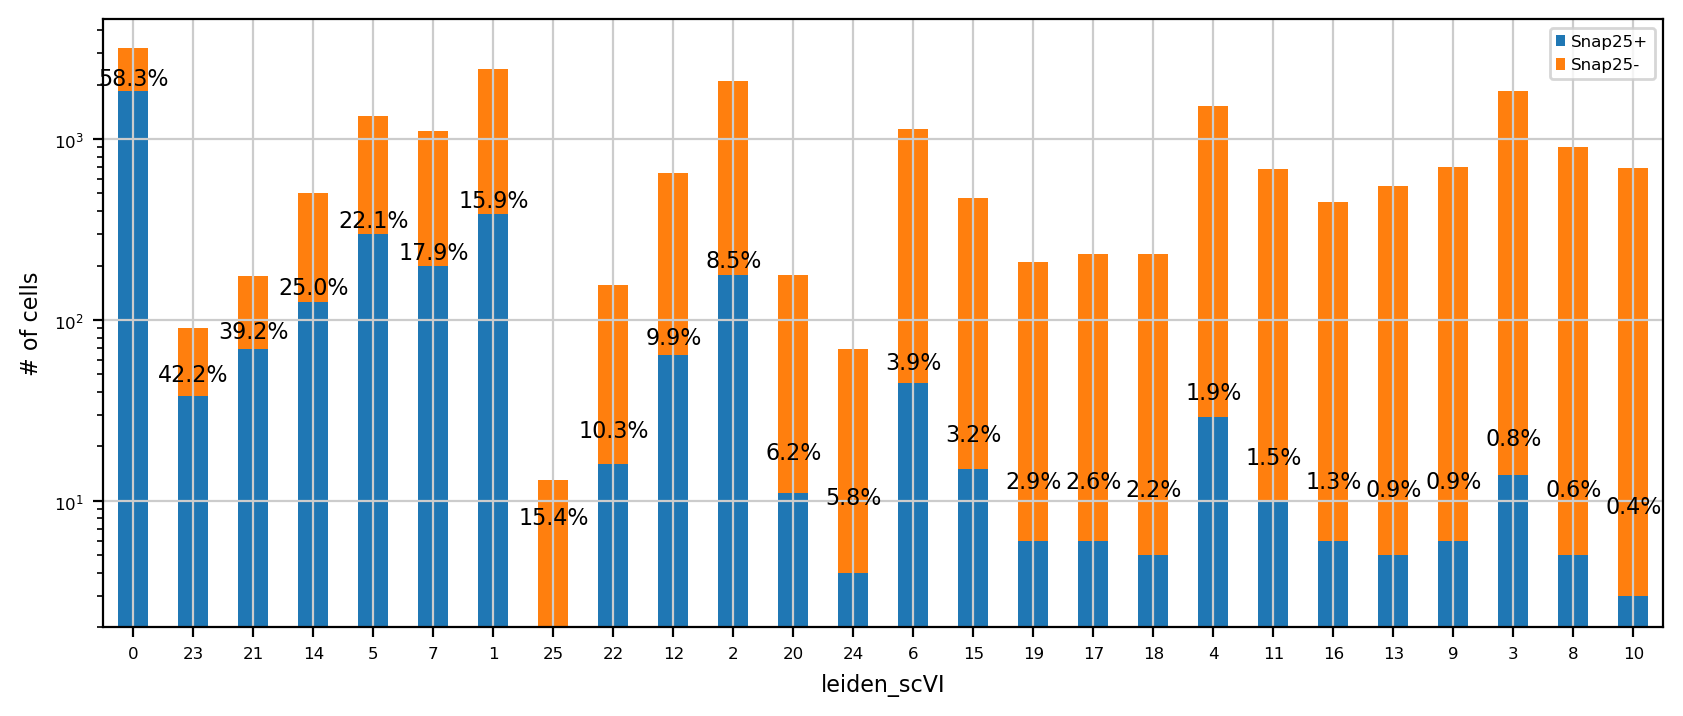

In [102]:
ax = scez.add_marker_feature(
    adata,marker='Snap25',marker_name='Snap25 label',clusters_name='leiden_scVI'
)

# plt.savefig('celltyping/percent_in_clust_denoised_Snap25.pdf')
# # show plot
# plt.show()

### Label Sox11
Divide cells into `Sox11+` and `'Sox11-` populations

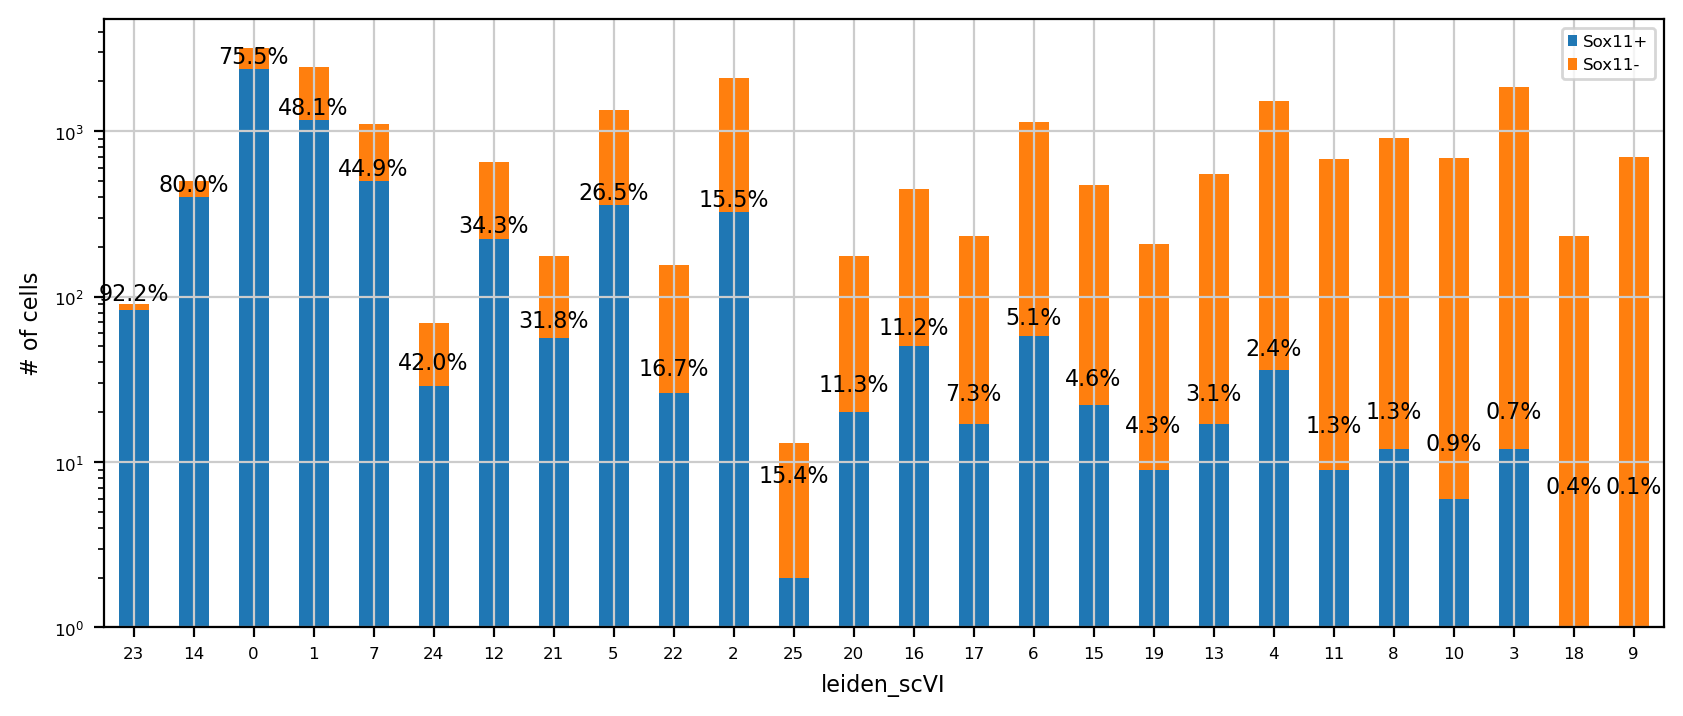

In [103]:
ax = scez.add_marker_feature(adata,marker='Sox11',marker_name='Sox11 label',clusters_name='leiden_scVI')

plt.savefig('celltyping/percent_in_clust_denoised_Sox11.pdf')
# show plot
plt.show()

### Label tdT+/-
Divide cells into `Gt(ROSA)26Sor+` and `'Gt(ROSA)26Sor-` populations

In [104]:
tdT_gene = "Gt(ROSA)26Sor"

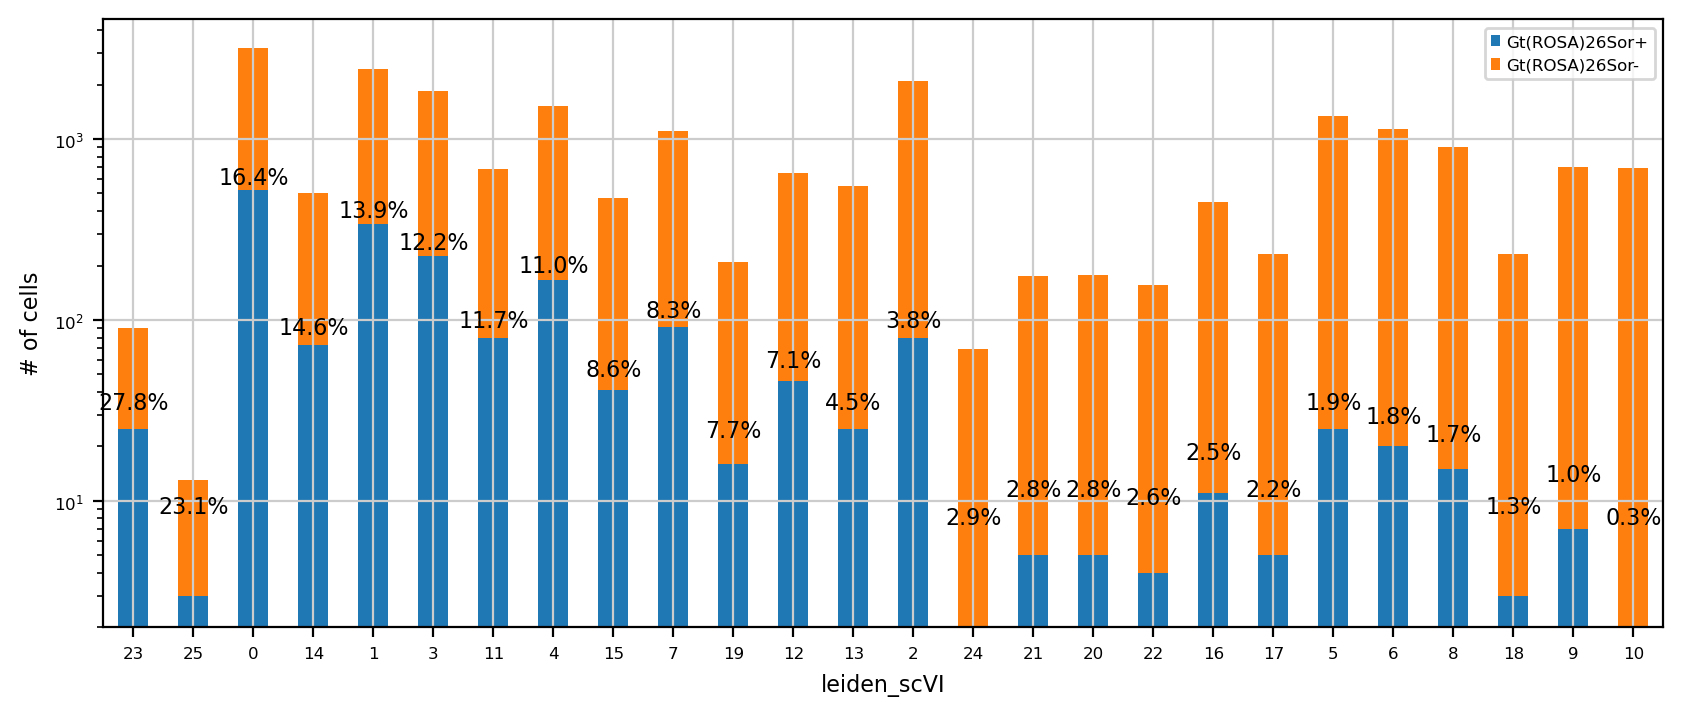

In [105]:
ax = scez.add_marker_feature(adata,marker=tdT_gene,marker_name='TdT label',clusters_name='leiden_scVI')

plt.savefig('celltyping/percent_in_clust_denoised_TdT.pdf')
# show plot
plt.show()

In [106]:
leiden_list = []
for l in adata.obs.leiden_scVI:
    if int(l) in [0,1,2,5,7,12,
                  #13,
                  14,15,
                  19,20,21,22,23,24,25]: leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [107]:
d = pd.DataFrame(adata.obs['label'] == 'Neuron').groupby('label').size()

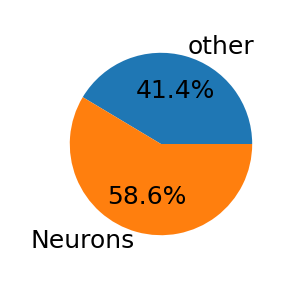

In [108]:
fig = plt.figure(figsize =(1, 1),dpi=150)
plt.pie(d.values,labels=['other','Neurons'],autopct='%1.1f%%')
# show plot
plt.show()

## Split dataset

In [177]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [178]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

# Neurons

### sub-clustering

In [179]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [180]:
adata_neuron

AnnData object with n_obs × n_vars = 12663 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'final label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

In [181]:
sc.tl.pca(adata_neuron)

In [182]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_neuron, use_rep="X_scVI")
sc.tl.umap(adata_neuron, min_dist=0.1)

In [183]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.1)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


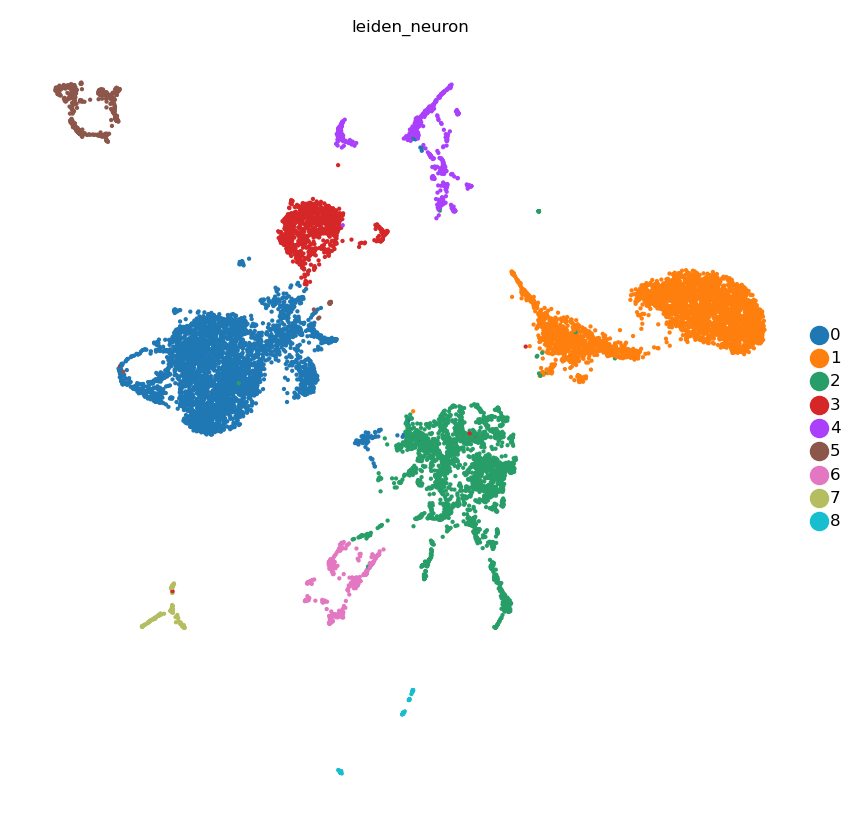

In [184]:
sc.pl.umap(adata_neuron, color='leiden_neuron')

### Save to file

Here, we need to think more about how to find subclusters!

In [185]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron.write_h5ad(results_file)

# Non-Neurons

In [186]:
adata_non_neuron

AnnData object with n_obs × n_vars = 8951 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'final label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

#### Scale

In [119]:
adata_non_neuron.layers['scaled'] = sc.pp.scale(adata_non_neuron, copy=True).X

In [120]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [121]:
# clustering(
#     adata_non_neuron,
#     rep='X_scVI',
#     n_comps = 30,
#     n_neighbor = 30,
#     res = 0.1,
#     key="leiden_non_neuron"
# )

In [122]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.1)

In [123]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


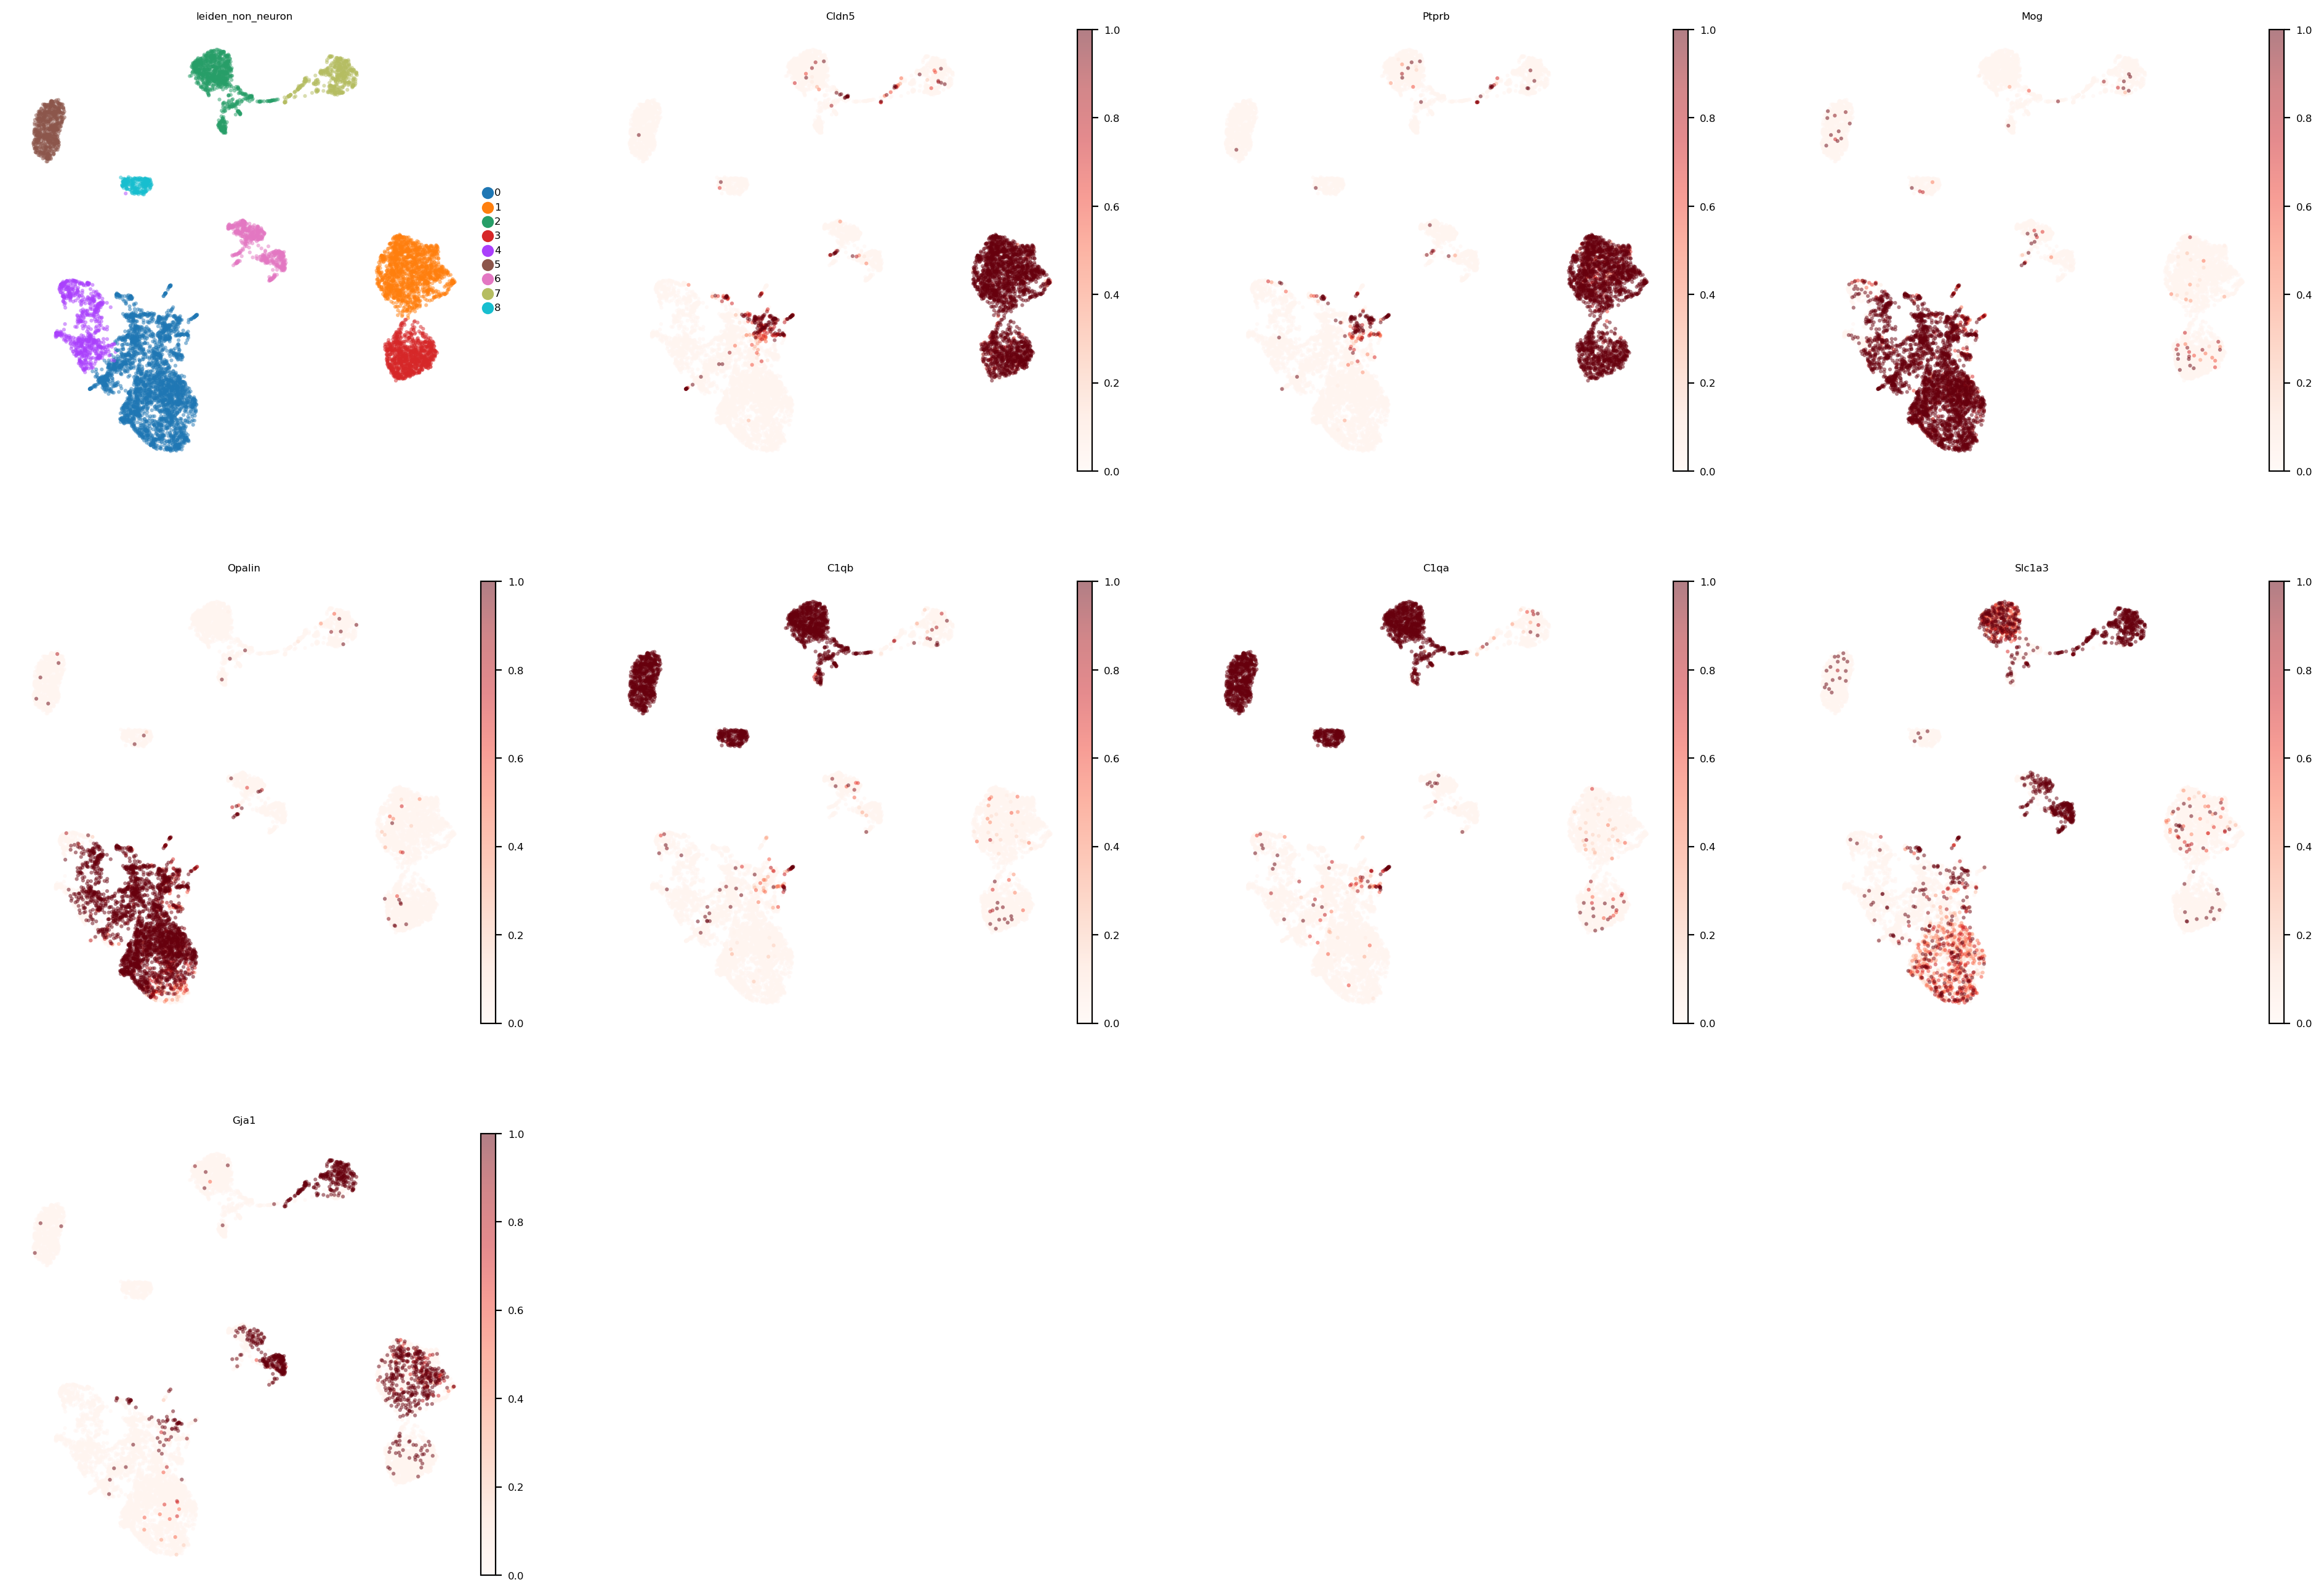

In [124]:
sc.pl.umap(
    adata_non_neuron, 
    color=['leiden_non_neuron'] + 
    [gene for _,genes in not_neuron_genes.items() for gene in genes],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    layer='scaled',
)

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Oligodentrocyte, Microglia, etc.


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


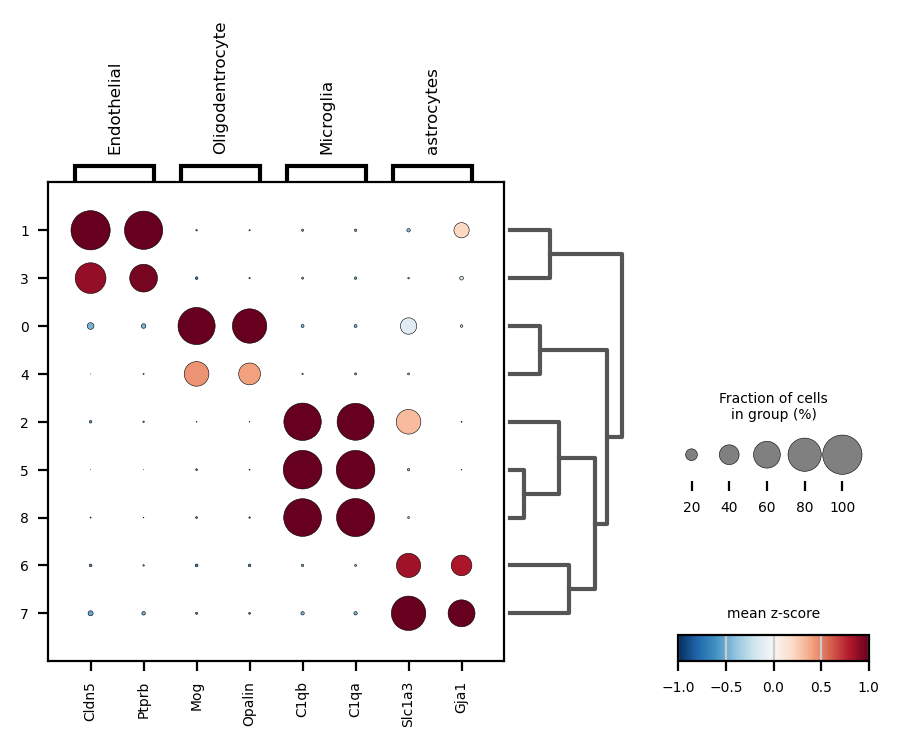

In [125]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [126]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    if int(l) in [2,5,8]: leiden_list.append('Microglia')
    elif int(l) in [6,7]: leiden_list.append('Astrocytes')
    elif int(l) in [1,3]: leiden_list.append('Endothelial')
    elif int(l) in [0,4]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [127]:
sc.tl.dendrogram(adata_non_neuron,'label') 

categories: Astrocytes, Endothelial, Microglia, etc.
var_group_labels: Endothelial, Oligodentrocyte, Microglia, etc.


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


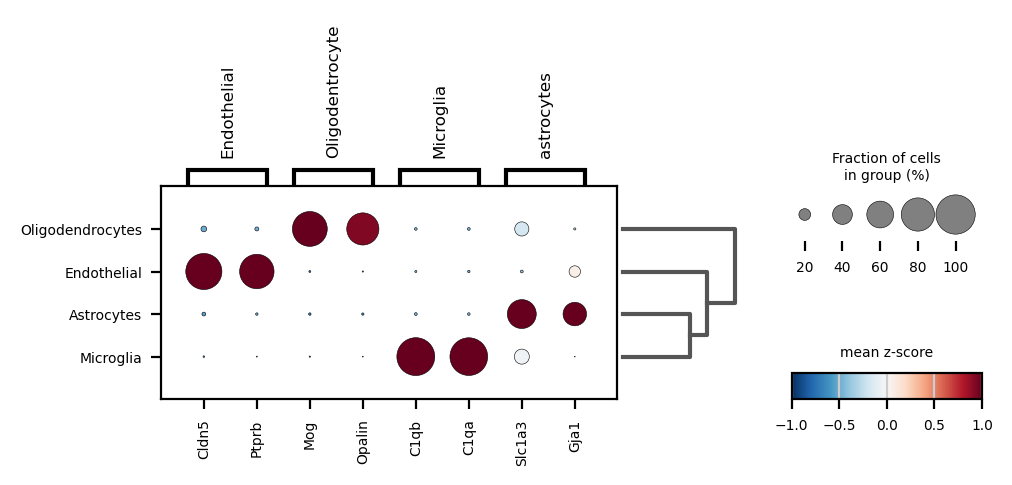

In [128]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/sc

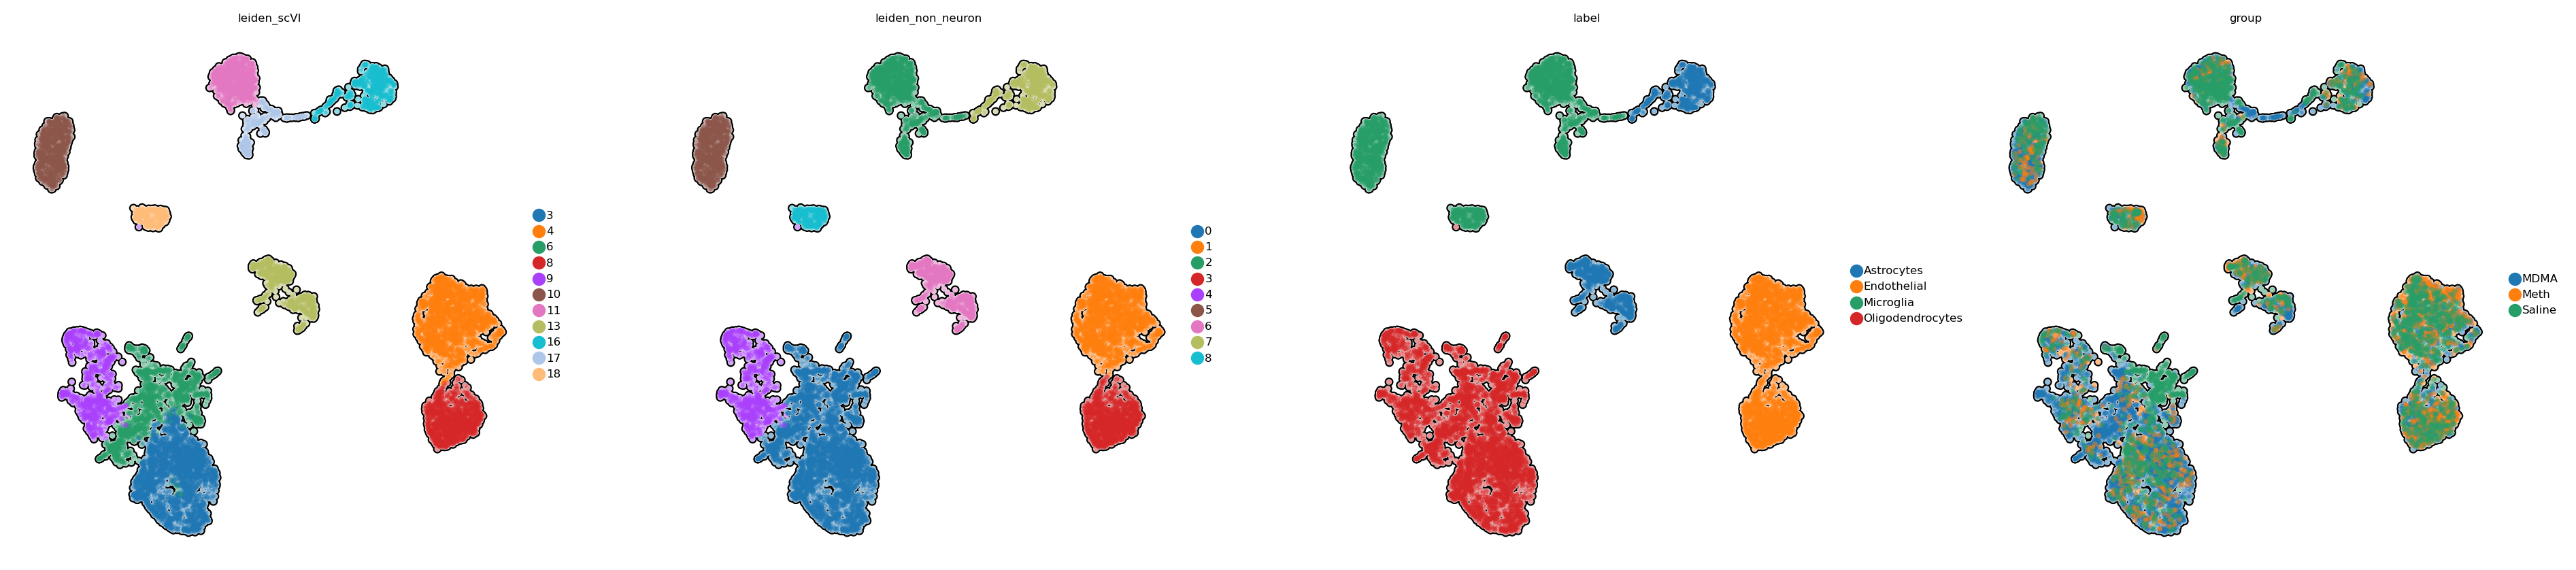

In [129]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'leiden_scVI',
        'leiden_non_neuron',
        'label',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

In [37]:
# sc.tl.rank_genes_groups(adata_non_neuron, 'label', 
#                         n_genes=adata_non_neuron.shape[1], method='t-test'
#                        )

In [38]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_non_neuron, 
#     # groupby=['label'],
#     n_genes=5,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     # groups=['12','10','6','9'],
#     vmin=-8, vmax=8, cmap='RdBu_r',
# )

In [39]:
# non_neuron_ranks = rank_genes_to_df(adata_non_neuron, n = 50)
# non_neuron_ranks
# Snap25_pos_rankdf.to_csv('celltyping/Snap25_pos_rank_genes.csv',index=False)

In [40]:
# non_neuron_ranks

##### 
save :)

In [130]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

# All data

In [169]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = ad.read_h5ad(results_file)

In [170]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = ad.read_h5ad(results_file)

In [187]:
adata = ad.concat([adata_neuron, adata_non_neuron])

In [188]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = 'neuron'#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(list(adata.obs['final label']))

In [189]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'final label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

In [191]:
adata.obs.loc[adata_neuron.obs_names,'leiden_neuron'] = list(adata_neuron.obs.leiden_neuron)
adata.obs['leiden_neuron'] = pd.Categorical(list(adata.obs['leiden_neuron']))

#### scale

In [194]:
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

In [195]:
sc.pp.pca(adata,n_comps=30)

In [196]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI",n_neighbors=30)
sc.tl.umap(adata, min_dist=0.1)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


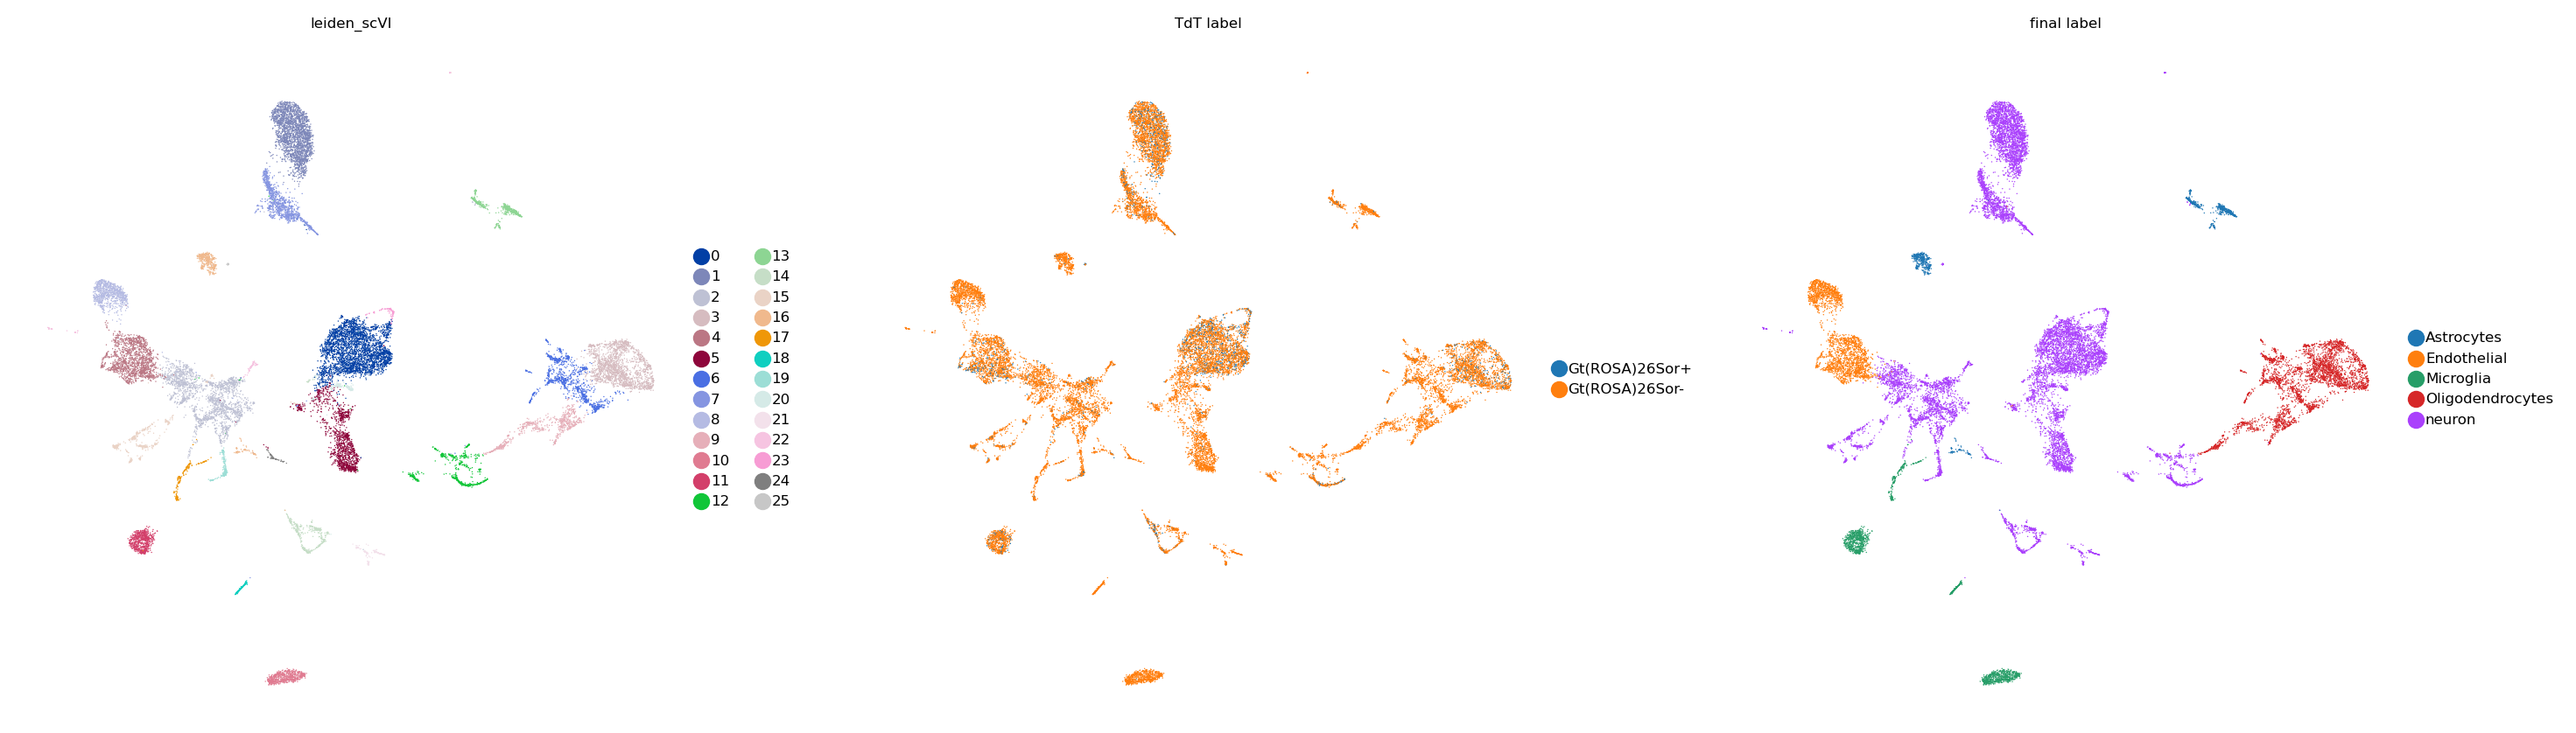

‘figures/umap_20230313.pdf’ -> ‘celltyping/umap_20230313.pdf’


In [197]:
sc.pl.umap(
    adata,
    color=[
        # 'group',
        'leiden_scVI',
        # 'leiden_neuron',
        "TdT label",
        # 'Snap25 label',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=.1,vmin=-.1,
    layer='scaled',
    color_map="Reds",
    frameon=False,
    # alpha=0.1,
    size=1,
    # legend_loc='on data',
    # add_outline=0.01,
    save = '_20230313'
)

!mv -v figures/umap_20230313.pdf celltyping/

### 

> - Groups and cell counts per group (would you please get me updated cell counts for each group?)

> - Amount that are tdT positive (less than expected – would you please generate a new UMAP highlighting tdT expression?)

In [198]:
pd.DataFrame(
    adata.obs.groupby(['batch','final label']).size()
).rename(columns={0:'# of cells'}).to_excel('num_cell_per_group.xlsx')

### Save final `adata`

In [219]:
adata_final = adata.copy()

In [220]:
del adata_final.obsm, adata_final.raw, adata_final.var, adata_final.uns, adata_final.varm, adata_final.obsp

In [221]:
for col in adata_final.obs.filter(like=' label').columns:
    del adata_final.obs[col]

In [222]:
results_file = 'preprocessing/adata-annotated.h5ad.gz'

adata_final.write_h5ad(results_file)

In [228]:
adata_final.to_df('counts').T.to_csv('preprocessing/adata-annotated-counts.csv.gz',compression='gzip')

In [217]:
adata_final.obs.to_csv('preprocessing/adata-annotated-meta.csv.gz',compression='gzip')

In [230]:
ls -lh preprocessing/adata-annotated*

-rw-rw-r--. 1 aarab aarab  30M Apr  3  2023 preprocessing/adata-annotated-counts.csv.gz
-rw-rw-r--. 1 aarab aarab 3.3G Apr  3 18:35 preprocessing/adata-annotated.h5ad.gz
-rw-rw-r--. 1 aarab aarab 145K Apr  3 18:35 preprocessing/adata-annotated-meta.csv.gz


# 

In [208]:
!date

Mon Apr  3 18:31:36 PDT 2023
